In [2]:
import pandas as pd
import sqlite3
import os
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.pipeline import make_pipeline

os.makedirs("stage22_outputs", exist_ok=True)

conn = sqlite3.connect(r"C:\Users\ADMIN\smart agricultural analytics\agriculture.db")
df = pd.read_sql("SELECT * FROM agri_yield_train_selected", conn)
conn.close()

In [3]:
features = [
    "NDVI_Temperature", "OrganicMatter_Sand",
    "Temperature_Rainfall", "sand_pct", "NDVI_Rainfall",
    "soil_ph", "organic_matter", "Humidity_Rainfall",
    "Temperature_Humidity", "rainfall"
]

X = df[features]
y = df["yield"]

model = make_pipeline(
    SimpleImputer(strategy="median"),
    GradientBoostingRegressor(
        n_estimators=100, max_depth=2,
        learning_rate=0.03, random_state=42
    )
)

model.fit(X, y)
print("Model trained successfully")

Model trained successfully


In [4]:
importance = model.named_steps[
    "gradientboostingregressor"
].feature_importances_

result = pd.DataFrame({
    "Feature": features,
    "Importance": importance
}).sort_values("Importance", ascending=False)

result.to_csv("stage22_outputs/feature_importance.csv", index=False)
print(result)

                Feature  Importance
1    OrganicMatter_Sand    0.176862
4         NDVI_Rainfall    0.167485
0      NDVI_Temperature    0.136583
9              rainfall    0.112481
5               soil_ph    0.087254
2  Temperature_Rainfall    0.086697
6        organic_matter    0.078496
8  Temperature_Humidity    0.076863
7     Humidity_Rainfall    0.064450
3              sand_pct    0.012829


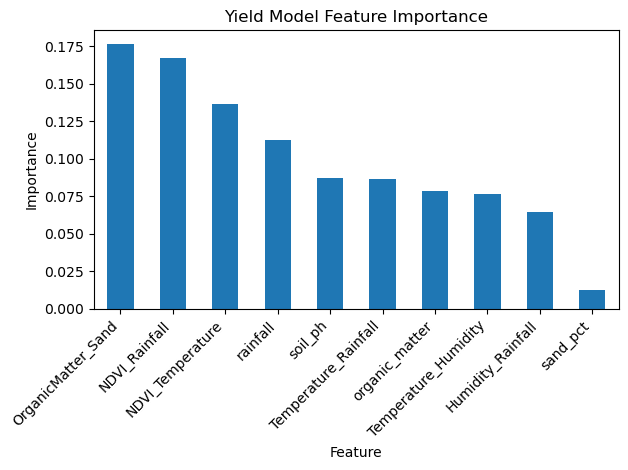

In [5]:
result.plot(x="Feature", y="Importance", kind="bar", legend=False)

plt.ylabel("Importance")
plt.title("Yield Model Feature Importance")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("stage22_outputs/feature_importance.png")
plt.show()

In [6]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    model, X, y,
    n_repeats=5,
    random_state=42,
    scoring="neg_mean_absolute_error"
)

perm_df = pd.DataFrame({
    "Feature": features,
    "Importance": perm.importances_mean
}).sort_values("Importance", ascending=False)

perm_df.to_csv(
    "stage22_outputs/permutation_importance.csv",
    index=False
)

print(perm_df)

                Feature  Importance
1    OrganicMatter_Sand    0.796235
4         NDVI_Rainfall    0.681494
0      NDVI_Temperature    0.416797
2  Temperature_Rainfall    0.374148
9              rainfall    0.370882
6        organic_matter    0.307528
5               soil_ph    0.254159
8  Temperature_Humidity    0.201514
7     Humidity_Rainfall    0.148150
3              sand_pct    0.013745
